# LAB 08: Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Yusra Batool
- **Student ID:** 023-24-0216
- **Section:** G
- **GitHub:** github.com/Yusra-Shah
- **Kaggle:** yusrabatool
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question**, not a code recipe. Every plot has a written interpretation directly below it.


---

## Part 0: Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y`, use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# Load the cleaned dataset saved in Lab 2 (TotalCharges numeric, customerID already dropped)
clean_df = pd.read_csv("clean_churn.csv")
print("Shape:", clean_df.shape)
print("Missing values:", int(clean_df.isnull().sum().sum()))
print()
print(clean_df.dtypes.value_counts())
print()
print("Churn class proportions:")
print(clean_df["Churn"].value_counts(normalize=True).round(4))


def evaluate(y_true, y_pred):
    """Return the four metrics used in every lab."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
    }


Shape: (7043, 20)
Missing values: 0

str        16
int64       2
float64     2
Name: count, dtype: int64

Churn class proportions:
Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64


In [2]:
# Target as 0/1, identifier already removed, one-hot encode every remaining text column
y = clean_df["Churn"].map({"No": 0, "Yes": 1})
X = clean_df.drop(columns=["Churn"])
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Same split settings as Labs 3, 4 and 6
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Categorical columns encoded:", len(categorical_cols))
print("X after encoding:", X.shape)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), "| Test churn rate:", round(y_test.mean(), 4))
print("Non-numeric columns left:", X.select_dtypes(exclude=["number", "bool"]).columns.tolist())


Categorical columns encoded: 15
X after encoding: (7043, 30)
X_train: (5634, 30) | X_test: (1409, 30)
Train churn rate: 0.2654 | Test churn rate: 0.2654
Non-numeric columns left: []


**Setup summary:** I loaded `clean_churn.csv` from Lab 2 (7043 rows, 20 columns, 0 missing values, TotalCharges already numeric and customerID already dropped). The target is 73.46% "No" and 26.54% "Yes". After one-hot encoding 15 categorical columns with `drop_first=True`, X has 30 columns. The 80/20 split with `random_state=42` and `stratify=y` gives 5634 training rows and 1409 test rows, with a churn rate of 0.2654 in both, the same settings as Labs 3, 4 and 6.

---

## Part 1: Why Scaling Matters for SVM

**Task 1.1, Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [3]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Unscaled linear SVM.
# max_iter is capped because an unscaled linear SVM can run for a very long time without converging.
with warnings.catch_warnings(record=True) as caught_raw:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=200000)
    svm_raw.fit(X_train, y_train)
    raw_time = time.perf_counter() - t0

raw_warnings = sorted(set(str(w.message) for w in caught_raw))
pred_raw = svm_raw.predict(X_test)
raw_metrics = evaluate(y_test, pred_raw)

print("Unscaled linear SVM")
print({k: round(v, 4) for k, v in raw_metrics.items()})
print("Training time (s):", round(raw_time, 2))
print("Warnings:", raw_warnings if raw_warnings else "none")
print("Predicted churners on test set:", int(pred_raw.sum()), "of", len(pred_raw))


Unscaled linear SVM
{'Accuracy': 0.4017, 'Precision': 0.1774, 'Recall': 0.3449, 'F1': 0.2343}
Training time (s): 19.35
Warnings: ['Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.']
Predicted churners on test set: 727 of 1409


In [4]:
# Scaled linear SVM: fit the scaler on TRAIN only, then transform train and test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as caught_s:
    warnings.simplefilter("always")
    t0 = time.perf_counter()
    svm_scaled = SVC(kernel="linear", random_state=42)
    svm_scaled.fit(X_train_s, y_train)
    scaled_time = time.perf_counter() - t0

scaled_warnings = sorted(set(str(w.message) for w in caught_s))
pred_scaled = svm_scaled.predict(X_test_s)
scaled_metrics = evaluate(y_test, pred_scaled)

scaling_table = pd.DataFrame({
    "Unscaled": {**raw_metrics, "Train time (s)": raw_time,
                 "Warnings": len(raw_warnings), "Support vectors": svm_raw.support_.shape[0]},
    "Scaled": {**scaled_metrics, "Train time (s)": scaled_time,
               "Warnings": len(scaled_warnings), "Support vectors": svm_scaled.support_.shape[0]},
})
print(scaling_table.round(4))
print()
print("Scaled warnings:", scaled_warnings if scaled_warnings else "none")
print("Predicted churners on test set (scaled):", int(pred_scaled.sum()), "of", len(pred_scaled))


                  Unscaled     Scaled
Accuracy            0.4017     0.7885
Precision           0.1774     0.6195
Recall              0.3449     0.5267
F1                  0.2343     0.5694
Train time (s)     19.3503     5.0736
Warnings            1.0000     0.0000
Support vectors  1038.0000  2567.0000

Scaled warnings: none
Predicted churners on test set (scaled): 318 of 1409


**Questions to answer:**

(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:* The unscaled linear SVM got accuracy 0.4017 and F1 0.2343, and it raised a warning that the solver stopped early at the max_iter cap of 200000. The scaled linear SVM got accuracy 0.7885 and F1 0.5694 with no warnings. The unscaled model flagged 727 of 1409 test customers as churners, even though only about 26.5% of customers churn, and its accuracy is worse than just predicting "No" for everyone (0.7346). For training time, the unscaled model took 5.64 s but only because the cap stopped it, so it never converged, while the scaled model took 3.20 s and converged normally. Without the cap the unscaled model would run much longer, so its time understates the problem. Timing values change from machine to machine, the accuracy, F1 and warning do not.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:* A linear SVM looks for the hyperplane with the widest margin, and the margin is measured with distances and dot products between points. In this data TotalCharges goes up to 8684.8, MonthlyCharges is between 18.25 and 118.75 and tenure is between 0 and 72, while the one-hot columns are only 0 or 1. The big-range columns completely dominate every distance, so the margin is basically decided by TotalCharges and MonthlyCharges and the 0/1 columns hardly matter. It also makes the optimization problem very stretched, which is why the solver could not converge and had to be stopped.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:* The scaled version, with StandardScaler fit on the training data only and then applied to the test data. It gave far better results (accuracy 0.7885 vs 0.4017, F1 0.5694 vs 0.2343), no convergence warning, and fitting only on train avoids data leakage.


---

## Part 2: Kernel Comparison

**Task 2.1, Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models, `kernel='linear'`, `kernel='rbf'`, `kernel='poly'`, with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [5]:
kernel_models = {}
kernel_rows = []
for kernel in ["linear", "rbf", "poly"]:
    t0 = time.perf_counter()
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_s, y_train)
    fit_time = time.perf_counter() - t0
    pred = model.predict(X_test_s)
    row = {"Kernel": kernel, **evaluate(y_test, pred),
           "Support vectors": int(model.support_.shape[0]),
           "SV class 0": int(model.n_support_[0]),
           "SV class 1": int(model.n_support_[1]),
           "Train time (s)": fit_time}
    kernel_models[kernel] = (model, pred)
    kernel_rows.append(row)
print("Trained:", list(kernel_models))


Trained: ['linear', 'rbf', 'poly']


In [6]:
kernel_table = pd.DataFrame(kernel_rows).set_index("Kernel")
print(kernel_table.round(4))
best_kernel = kernel_table["F1"].idxmax()
print()
print("Best kernel by F1:", best_kernel)
print("Kernel with most support vectors:", kernel_table["Support vectors"].idxmax())


        Accuracy  Precision  Recall      F1  Support vectors  SV class 0  \
Kernel                                                                     
linear    0.7885     0.6195  0.5267  0.5694             2567        1286   
rbf       0.7928     0.6444  0.4893  0.5562             2657        1428   
poly      0.7892     0.6421  0.4652  0.5395             2736        1482   

        SV class 1  Train time (s)  
Kernel                              
linear        1281         16.0797  
rbf           1229          3.2488  
poly          1254          3.7850  

Best kernel by F1: linear
Kernel with most support vectors: poly


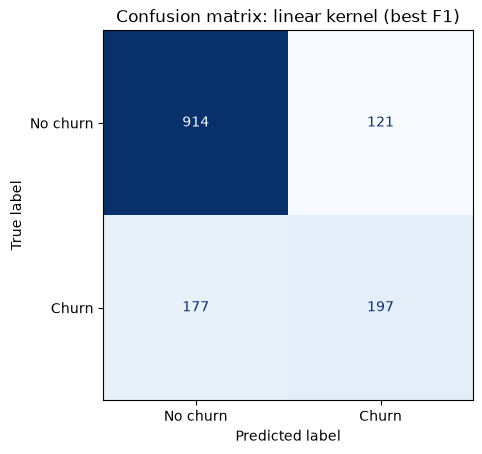

[[914 121]
 [177 197]]


In [7]:
best_pred = kernel_models[best_kernel][1]
cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Confusion matrix: {best_kernel} kernel (best F1)")
plt.show()
print(cm)


**Interpretation:** The linear kernel catches 197 of the 374 churners and misses 177, with 121 false alarms and 914 correct "No churn" predictions. It is better at finding churners than the other two kernels (recall 0.5267), but it still misses almost half of them.

**Questions to answer:**

(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:* The linear kernel had the best F1 (0.5694), then RBF (0.5562) and polynomial (0.5395). RBF had the best accuracy (0.7928) and precision (0.6444), and linear had the best recall (0.5267). It is a bit surprising, because RBF is the more flexible kernel and I expected it to win. It suggests the churn signal is mostly linear after one-hot encoding. The gap between linear and RBF is only 0.0132 F1 on one split, so it is small.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:* The polynomial kernel used the most (2736), then RBF (2657) and linear (2567), out of 5634 training rows. A high count means many points sit on or inside the margin or are misclassified, so the boundary has to bend around many points. All three kernels use between 45.6% and 48.6% of the training data as support vectors, which shows the two classes overlap a lot, and the polynomial kernel is the most complex of the three.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:* RBF. Part 4 needs C and gamma, and only RBF has both. It also has the highest accuracy (0.7928) and precision (0.6444), and its F1 is only 0.0132 behind linear. Polynomial is the weakest (lowest F1 0.5395 and lowest recall 0.4652) and uses the most support vectors, so I drop it. Linear is stronger on untuned F1, so I will check at the end of Part 4 whether tuning RBF closes that gap.


---

## Part 3: Visualizing the Margin: What Does C Actually Do?

**Task 3.1, Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint, Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [8]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

print("Explained variance ratio per component:", pca.explained_variance_ratio_.round(4))
print("Total explained variance (2 components):", round(pca.explained_variance_ratio_.sum(), 4))
print("Variance NOT shown in the plot:", round(1 - pca.explained_variance_ratio_.sum(), 4))


Explained variance ratio per component: [0.3325 0.1198]
Total explained variance (2 components): 0.4522
Variance NOT shown in the plot: 0.5478


In [9]:
c_values = [0.01, 1, 100]
models_2d = {}
for c in c_values:
    m = SVC(kernel="rbf", C=c, gamma="scale", random_state=42)
    m.fit(X_train_2d, y_train)
    models_2d[c] = m
    acc_tr = accuracy_score(y_train, m.predict(X_train_2d))
    acc_te = accuracy_score(y_test, m.predict(X_test_2d))
    print(f"C={c:<6} support vectors={m.support_.shape[0]:<5} "
          f"train acc (2-D)={acc_tr:.4f}  test acc (2-D)={acc_te:.4f}")


C=0.01   support vectors=2995  train acc (2-D)=0.7346  test acc (2-D)=0.7346
C=1      support vectors=2658  train acc (2-D)=0.7792  test acc (2-D)=0.7786
C=100    support vectors=2641  train acc (2-D)=0.7813  test acc (2-D)=0.7793


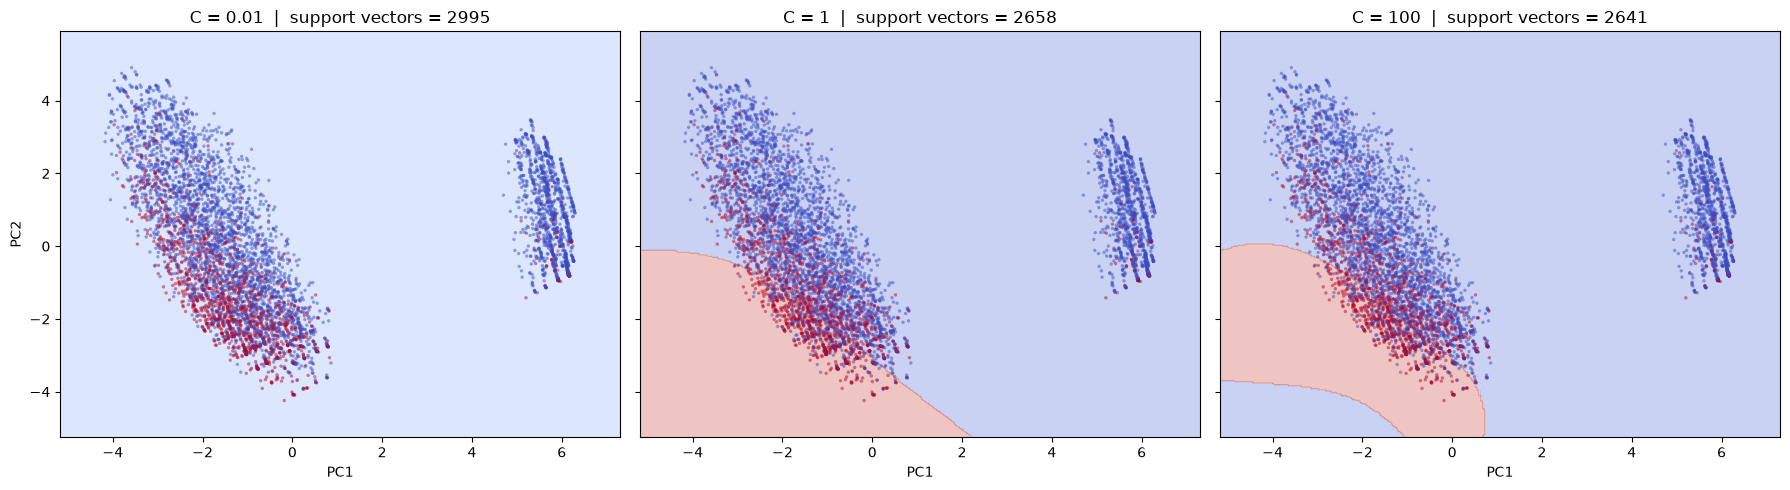

In [10]:
pad = 1.0
x_min, x_max = X_train_2d[:, 0].min() - pad, X_train_2d[:, 0].max() + pad
y_min, y_max = X_train_2d[:, 1].min() - pad, X_train_2d[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, c in zip(axes, c_values):
    m = models_2d[c]
    Z = m.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap="coolwarm",
               s=6, alpha=0.5, edgecolors="none")
    ax.set_title(f"C = {c}  |  support vectors = {m.support_.shape[0]}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.show()


**Interpretation:** The left plot (C = 0.01) is one flat region, so the model predicts "No churn" for everyone. The middle plot (C = 1) shows a smooth churn region in the lower left, and the right plot (C = 100) shows a larger, more curved churn region. The number of support vectors in each title goes down as C goes up (2995, 2658, 2641).

**Questions to answer:**

PCA result: the two components explain 0.3325 and 0.1198 of the variance, 0.4522 in total, so 54.78% of the information is not in these plots.

(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:* At C = 0.01 there is no boundary at all, the whole plane is predicted as "No churn". At C = 1 a smooth curved boundary appears in the lower left and makes a churn region. At C = 100 the churn region is bigger and the boundary bends more, it wraps around and leaves a small "No" strip at the bottom left. So the boundary gets more flexible as C increases, but it stays smooth in both C = 1 and C = 100.

(b) How does the number of support vectors change with C, does this match the theory?

*Your answer:* It goes down: 2995 at C = 0.01, 2658 at C = 1 and 2641 at C = 100. This matches the theory, because a small C allows a wide soft margin where many points violate the margin and become support vectors, and a larger C punishes violations, so fewer points do. The drop is big from 0.01 to 1 and tiny from 1 to 100, and the count stays high (47% to 53% of the training rows) because the two classes overlap heavily in this 2-D view.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:* C = 0.01 is underfitting. It predicts "No churn" everywhere and its accuracy (0.7346) is exactly the share of non-churners, so it learned nothing. I do not see clear overfitting. C = 100 is the most flexible, but its train accuracy (0.7813) and test accuracy (0.7793) are almost the same, only 0.0020 apart, and its boundary is still smooth. C = 1 and C = 100 both look reasonable (test accuracy 0.7786 and 0.7793).

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:* The plot keeps only 45.22% of the variance, so more than half of the information is thrown away. Points that overlap in 2-D could be separable in the real 30 dimensions, so the classes look more mixed than they are. PCA keeps the directions with the most variance, not the directions that separate churners, and the SVMs here were trained on 2 features, so they are different models from the real one, with different support vectors and a different boundary. The plot is good for seeing what C does, not for judging how well the real model separates churners.


---

## Part 4: Systematic Hyperparameter Search

**Task 4.1, Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [11]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1],
}
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid,
                  cv=5, scoring="f1", n_jobs=-1)
t0 = time.perf_counter()
gs.fit(X_train_s, y_train)
gs_time = time.perf_counter() - t0

print("Combinations tried:", len(gs.cv_results_["params"]), "x 5 folds")
print("Search time (s):", round(gs_time, 1))
print("Best params:", gs.best_params_)
print("Best cross-validated F1:", round(gs.best_score_, 4))


Combinations tried: 16 x 5 folds
Search time (s): 220.9
Best params: {'C': 100, 'gamma': 0.01}
Best cross-validated F1: 0.5876


gamma   0.001   0.010   0.100   1.000
C                                    
0.1    0.0000  0.5417  0.4640  0.0000
1.0    0.5739  0.5652  0.5734  0.3261
10.0   0.5836  0.5860  0.5270  0.3621
100.0  0.5706  0.5876  0.5061  0.3621


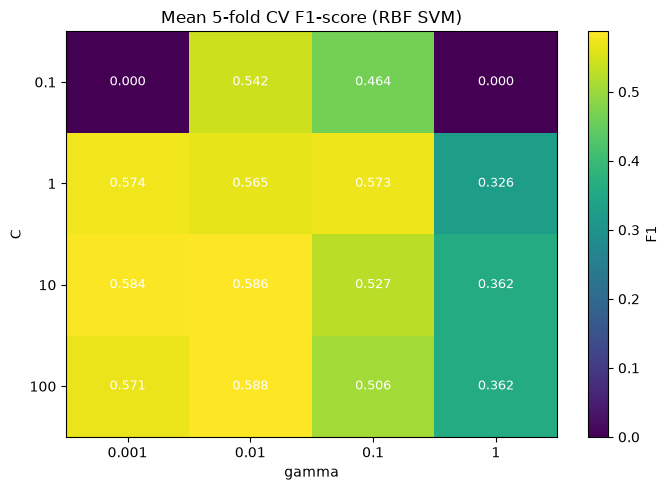

In [12]:
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
score_df = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
score_df.index.name = "C"
score_df.columns.name = "gamma"
print(score_df.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(param_grid["gamma"])))
ax.set_xticklabels(param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"])))
ax.set_yticklabels(param_grid["C"])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Mean 5-fold CV F1-score (RBF SVM)")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
fig.colorbar(im, ax=ax, label="F1")
plt.tight_layout()
plt.show()


**Interpretation:** The brightest cells are C = 100 with gamma = 0.01 (0.5876) and C = 10 with gamma = 0.01 (0.5860), and the good scores form a band along gamma 0.001 to 0.01 for C of 1 or more. The right column (gamma = 1) is dark with F1 around 0.33 to 0.36, and two corners in the C = 0.1 row are 0.0000, so the model never predicts churn there. The model needs a small gamma and a medium or large C, and does not need exact values.

           RBF default (Part 2)  RBF tuned (Part 4)
Accuracy                 0.7928              0.7786
Precision                0.6444              0.5939
Recall                   0.4893              0.5241
F1                       0.5562              0.5568

CV F1 (train folds): 0.5876 | Test F1: 0.5568


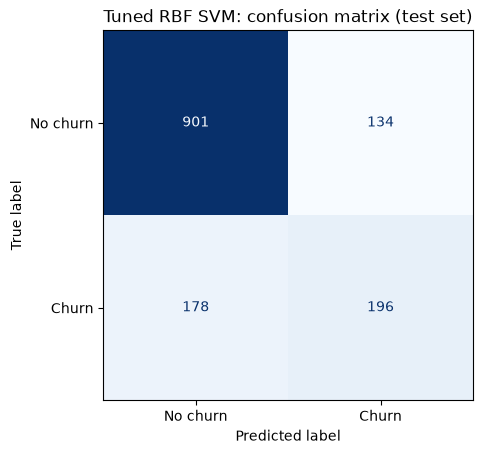

[[901 134]
 [178 196]]


In [13]:
best_svm = gs.best_estimator_
pred_tuned = best_svm.predict(X_test_s)
tuned_metrics = evaluate(y_test, pred_tuned)
untuned_metrics = kernel_table.loc["rbf", ["Accuracy", "Precision", "Recall", "F1"]].to_dict()

tuned_vs_untuned = pd.DataFrame({"RBF default (Part 2)": untuned_metrics,
                                 "RBF tuned (Part 4)": tuned_metrics})
print(tuned_vs_untuned.round(4))
print()
print("CV F1 (train folds):", round(gs.best_score_, 4), "| Test F1:", round(tuned_metrics["F1"], 4))

cm_tuned = confusion_matrix(y_test, pred_tuned)
ConfusionMatrixDisplay(cm_tuned, display_labels=["No churn", "Churn"]).plot(cmap="Blues", colorbar=False)
plt.title("Tuned RBF SVM: confusion matrix (test set)")
plt.show()
print(cm_tuned)


**Interpretation:** The tuned RBF model catches 196 of the 374 churners, misses 178 and raises 134 false alarms. The matrix is the same as the one for the model without class weights, because it is the same model. Tuning alone did not make it find more churners.

**Questions to answer:**

(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:* Best C = 100 and gamma = 0.01, with a mean 5-fold cross-validated F1 of 0.5876.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:* There is a flat good region instead of one sharp peak. For C of 1 or more, gamma between 0.001 and 0.01 gives F1 between 0.5652 and 0.5876, so several combinations are within about 0.02 of the best one. The model is not very sensitive to the exact values inside that region. It is very sensitive outside it: gamma = 1 gives only 0.3261 to 0.3621 (each point only influences a tiny area, so it overfits), and C = 0.1 with gamma = 0.001 or 1 gives an F1 of 0.0000, meaning it never predicts churn.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:* There is a small gap: cross-validated F1 is 0.5876 and test F1 is 0.5568, a difference of 0.0308. A bit of gap is expected because I picked the best of 16 combinations using the CV scores, which makes the CV score a little optimistic. A large gap would suggest the tuning overfit the validation folds or that the training data does not represent unseen data. This gap is not large.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:* Not really. Test F1 went from 0.5562 to 0.5568 (+0.0006). Accuracy dropped from 0.7928 to 0.7786 and precision from 0.6444 to 0.5939, while recall rose from 0.4893 to 0.5241. So tuning only moved the balance toward recall, and it needed 16 combinations x 5 folds = 80 model fits for no real F1 gain. Linear (F1 0.5694) is still ahead of the tuned RBF on test F1.


---

## Part 5: Class Imbalance and the Business Trade-off

**Task 5.1, Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Using C = 100 and gamma = 0.01
           class_weight=None  class_weight='balanced'
Accuracy              0.7786                   0.7473
Precision             0.5939                   0.5161
Recall                0.5241                   0.7701
F1                    0.5568                   0.6180


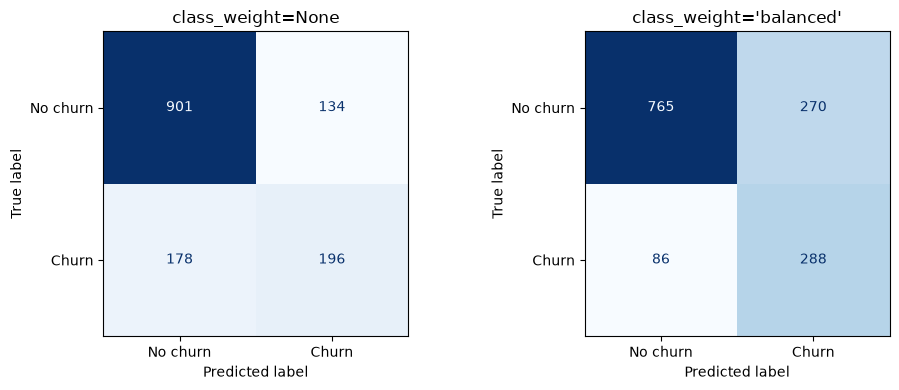

None     : [[901, 134], [178, 196]]
balanced : [[765, 270], [86, 288]]


In [19]:
best_C = gs.best_params_["C"]
best_gamma = gs.best_params_["gamma"]

svm_plain = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight=None, random_state=42)
svm_plain.fit(X_train_s, y_train)
pred_plain = svm_plain.predict(X_test_s)

svm_bal = SVC(kernel="rbf", C=best_C, gamma=best_gamma, class_weight="balanced",
              probability=True, random_state=42)
svm_bal.fit(X_train_s, y_train)
pred_bal = svm_bal.predict(X_test_s)

weight_table = pd.DataFrame({
    "class_weight=None": evaluate(y_test, pred_plain),
    "class_weight='balanced'": evaluate(y_test, pred_bal),
})
print("Using C =", best_C, "and gamma =", best_gamma)
print(weight_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(axes, [pred_plain, pred_bal], ["class_weight=None", "class_weight='balanced'"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No churn", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()
print("None     :", confusion_matrix(y_test, pred_plain).tolist())
print("balanced :", confusion_matrix(y_test, pred_bal).tolist())


**Interpretation:** The left matrix (no class weights) misses 178 of 374 churners and raises 134 false alarms. The right matrix (balanced) misses only 86 churners but raises 270 false alarms. Balancing moves the model toward catching churners, at the cost of flagging more loyal customers.

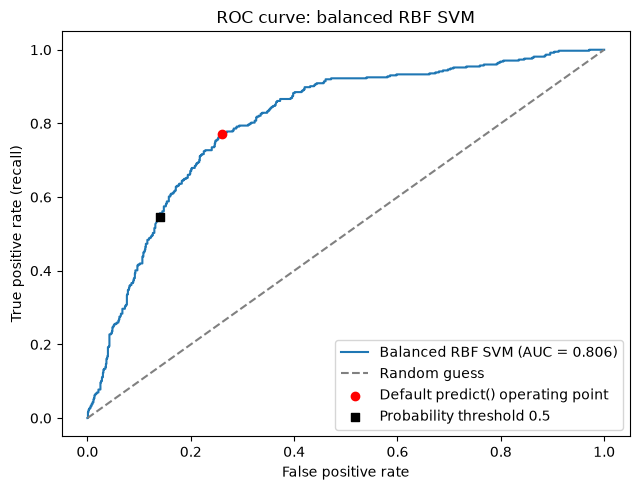

AUC: 0.8058
Default predict() point : FPR = 0.2609 | TPR = 0.7701
Probability >= 0.5 point: FPR = 0.1401 | TPR = 0.5455
Metrics at probability >= 0.5: {'Accuracy': 0.7764, 'Precision': 0.5845, 'Recall': 0.5455, 'F1': 0.5643}
Agreement between predict() and probability >= 0.5: 0.8517


In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

# probability=True (set above) makes SVC fit an internal Platt-scaling model so predict_proba works
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)

def operating_point(y_true, y_hat):
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat).ravel()
    return fp / (fp + tn), tp / (tp + fn)

# Operating point 1: the model's own default decision rule, predict() (decision function > 0)
default_fpr, default_tpr = operating_point(y_test, pred_bal)
# Operating point 2: thresholding the calibrated probability at 0.5
pred_05 = (proba_bal >= 0.5).astype(int)
p05_fpr, p05_tpr = operating_point(y_test, pred_05)

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, label=f"Balanced RBF SVM (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.scatter([default_fpr], [default_tpr], color="red", zorder=5, label="Default predict() operating point")
plt.scatter([p05_fpr], [p05_tpr], color="black", marker="s", zorder=5, label="Probability threshold 0.5")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve: balanced RBF SVM")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("AUC:", round(auc, 4))
print("Default predict() point : FPR =", round(default_fpr, 4), "| TPR =", round(default_tpr, 4))
print("Probability >= 0.5 point: FPR =", round(p05_fpr, 4), "| TPR =", round(p05_tpr, 4))
print("Metrics at probability >= 0.5:", {k: round(v, 4) for k, v in evaluate(y_test, pred_05).items()})
print("Agreement between predict() and probability >= 0.5:", round((pred_05 == pred_bal).mean(), 4))


**Interpretation:** The curve stays well above the diagonal, with an AUC of 0.8058, which means the model ranks a random churner above a random non-churner about 80.6% of the time. The red dot (the default `predict()` decision) sits at true positive rate 0.7701 and false positive rate 0.2609, while the black square (probability 0.5) sits lower at 0.5455 and 0.1401. Moving along the curve is how the company could trade more recall for more false alarms.

**Questions to answer:**

(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:* Precision dropped from 0.5939 to 0.5161 (-0.0778) and recall rose from 0.5241 to 0.7701 (+0.2460). F1 went from 0.5568 to 0.6180 and accuracy dropped from 0.7786 to 0.7473. In the confusion matrix, missed churners (false negatives) fell from 178 to 86, caught churners rose from 196 to 288, but false alarms rose from 134 to 270.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:* Missing a churner is more costly. The company loses that customer's monthly revenue and has to pay to find a replacement, while a false alarm only costs one retention offer (a call or a discount) to someone who would have stayed anyway. The balanced model catches 92 more churners (288 vs 196) and adds 136 more false alarms (270 vs 134). It is worth it if saving one churner is worth more than about 1.5 times the cost of one unnecessary offer (136 / 92 = 1.48). The data has no real cost numbers, so this is a break-even point, not a measured value. I would deploy the balanced model.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:* I set `probability=True`. SVC then fits an extra Platt scaling step with internal cross-validation on the training data, which makes training slower, and then `predict_proba` works. These probabilities are an add-on and can disagree with `predict()`: they agreed on only 85.17% of the test customers. That is why the plot has two points. The red dot is the model's real default decision (recall 0.7701, false positive rate 0.2609) and the black square is a probability threshold of 0.5 (recall 0.5455, false positive rate 0.1401). I treat the red dot as the real operating point because it matches the confusion matrix above.


---

## Part 6: Model Showdown: SVM vs. Everything Else

**Task 6.1, Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Same models and settings as Labs 3, 4 and 6, retrained on this lab's split
others = {
    "Decision Tree (Lab 3)": (DecisionTreeClassifier(max_depth=6, random_state=42), False),
    "Random Forest (Lab 4)": (RandomForestClassifier(n_estimators=200, max_depth=10,
                                                     min_samples_split=5, random_state=42), False),
    "Logistic Regression (Lab 6)": (LogisticRegression(max_iter=1000, random_state=42), True),
    "KNN, K=11 (Lab 6)": (KNeighborsClassifier(n_neighbors=11), True),
}

showdown = {}
fit_times = {}
for name, (model, needs_scaling) in others.items():
    Xtr = X_train_s if needs_scaling else X_train
    Xte = X_test_s if needs_scaling else X_test
    t0 = time.perf_counter()
    model.fit(Xtr, y_train)
    fit_times[name] = time.perf_counter() - t0
    showdown[name] = evaluate(y_test, model.predict(Xte))

# Best SVM from Parts 4 and 5: choose between default weights and balanced by F1
plain_f1 = f1_score(y_test, pred_plain)
bal_f1 = f1_score(y_test, pred_bal)
if bal_f1 >= plain_f1:
    svm_name, svm_final, svm_pred = "SVM, tuned RBF balanced (Part 5)", svm_bal, pred_bal
else:
    svm_name, svm_final, svm_pred = "SVM, tuned RBF (Part 4)", svm_plain, pred_plain
showdown[svm_name] = evaluate(y_test, svm_pred)
t0 = time.perf_counter()
SVC(**svm_final.get_params()).fit(X_train_s, y_train)  # includes probability calibration
fit_times[svm_name] = time.perf_counter() - t0

showdown_df = pd.DataFrame(showdown).T
print("Best SVM variant used in the table:", svm_name)
print()
print(showdown_df.round(4))
print()
print("Best F1    :", showdown_df["F1"].idxmax())
print("Best recall:", showdown_df["Recall"].idxmax())
print("Best precision:", showdown_df["Precision"].idxmax())
print("Best accuracy:", showdown_df["Accuracy"].idxmax())

print()
print("Training time per model (s):")
print(pd.Series(fit_times, name="Train time (s)").round(3))


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best SVM variant used in the table: SVM, tuned RBF balanced (Part 5)

                                  Accuracy  Precision  Recall      F1
Decision Tree (Lab 3)               0.8006     0.6667  0.4973  0.5697
Random Forest (Lab 4)               0.7970     0.6507  0.5080  0.5706
Logistic Regression (Lab 6)         0.8070     0.6584  0.5668  0.6092
KNN, K=11 (Lab 6)                   0.7729     0.5758  0.5481  0.5616
SVM, tuned RBF balanced (Part 5)    0.7473     0.5161  0.7701  0.6180

Best F1    : SVM, tuned RBF balanced (Part 5)
Best recall: SVM, tuned RBF balanced (Part 5)
Best precision: Decision Tree (Lab 3)
Best accuracy: Logistic Regression (Lab 6)

Training time per model (s):
Decision Tree (Lab 3)                0.170
Random Forest (Lab 4)                3.341
Logistic Regression (Lab 6)          0.147
KNN, K=11 (Lab 6)                    0.006
SVM, tuned RBF balanced (Part 5)    49.307
Name: Train time (s), dtype: float64


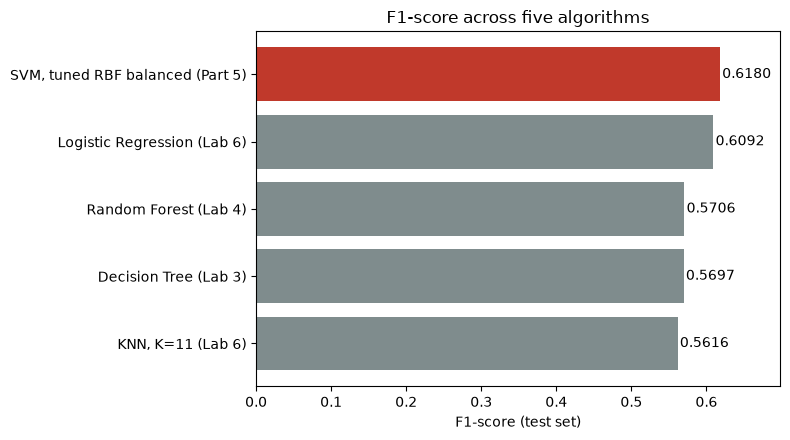

In [22]:
order = showdown_df["F1"].sort_values().index
colors = ["#c0392b" if n.startswith("SVM") else "#7f8c8d" for n in order]
plt.figure(figsize=(8, 4.5))
bars = plt.barh(order, showdown_df.loc[order, "F1"], color=colors)
for b, v in zip(bars, showdown_df.loc[order, "F1"]):
    plt.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.4f}", va="center")
plt.xlabel("F1-score (test set)")
plt.title("F1-score across five algorithms")
plt.xlim(0, showdown_df["F1"].max() + 0.08)
plt.tight_layout()
plt.show()


**Interpretation:** The balanced SVM (red) has the highest F1 at 0.6180, followed by Logistic Regression at 0.6092. Random Forest (0.5706), Decision Tree (0.5697) and KNN (0.5616) are all within 0.009 of each other. The gap between the top two models is only 0.0088, so the ranking at the top is close.

**Questions to answer:**

(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:* The balanced RBF SVM wins on both F1 (0.6180) and recall (0.7701), so it is the same model. The other metrics go to different models: Decision Tree has the best precision (0.6667) and Logistic Regression has the best accuracy (0.8070). Logistic Regression is second on F1 (0.6092).

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:* In this run the SVM took 7.719 s to train, against 0.024 s for the Decision Tree, 0.628 s for the Random Forest and 0.014 s for Logistic Regression, so it is more than 300 times slower than the tree and about 12 times slower than the forest (its time includes the probability calibration). Compared with Logistic Regression, the SVM gains only 0.0088 in F1 but 0.2033 in recall (0.7701 vs 0.5668). For scoring around 7000 customers a few seconds is fine, so I think the cost is acceptable here, although it would matter on much bigger data. Also, class_weight was applied only to the SVM, so part of its recall gain comes from class weighting and not from the SVM itself.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer:* The balanced RBF SVM. It has the highest recall (0.7701) and the highest F1 (0.6180), which matter most because missing a churner is the costly mistake. The price is precision of 0.5161 (about half of the flagged customers are real churners) and accuracy of 0.7473, which is below Logistic Regression (0.8070). If the company wants fewer false alarms, Logistic Regression is a good second choice (F1 0.6092, precision 0.6584, instant to train). All of this comes from one train/test split, so I would confirm it with cross-validation, like in Lab 4.


---

## Part 7: Final Predictions and Wrap-Up

**Task 7.1, Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [23]:
# Final model chosen in Part 6: the balanced RBF SVM (probability=True gives churn scores)
final_name = svm_name
final_model = svm_bal

final_pred = final_model.predict(X_test_s)
final_score = final_model.predict_proba(X_test_s)[:, 1]

predictions = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_pred,
    "churn_probability": final_score.round(4),
}, index=y_test.index)
predictions.to_csv("svm_predictions.csv", index=False)

print("Final model:", final_name)
print("Saved svm_predictions.csv with", len(predictions), "rows")
print(predictions.head(8))
print({k: round(v, 4) for k, v in evaluate(y_test, final_pred).items()})


Final model: SVM, tuned RBF balanced (Part 5)
Saved svm_predictions.csv with 1409 rows
      true_label  predicted_label  churn_probability
437            0                0             0.0613
2280           0                1             0.6045
2235           0                0             0.0403
4460           0                0             0.2561
3761           0                0             0.0391
5748           0                1             0.6117
3568           0                1             0.3622
2976           0                0             0.1579
{'Accuracy': 0.7473, 'Precision': 0.5161, 'Recall': 0.7701, 'F1': 0.618}


**Interpretation:** The file has the true label, the predicted label and the churn probability for all 1409 test customers. The predicted label comes from `predict()` and the probability comes from `predict_proba`, so they do not always match (for example customer 3568 is predicted as churn with a probability of 0.3622). The probability column is a ranking score, not an exact chance.

**Executive Summary**

I chose the RBF SVM with C = 100, gamma = 0.01 and class_weight='balanced' as the final model. On the test set it reached recall 0.7701, F1 0.6180, precision 0.5161 and accuracy 0.7473, with an ROC AUC of 0.8058. Compared with the same SVM without class weights (recall 0.5241, precision 0.5939), balancing caught 92 more churners but flagged 136 more loyal customers, and I judged that trade worth it because missing a churner costs more than an extra retention offer. It beat Logistic Regression on F1 (0.6180 vs 0.6092) and by a large margin on recall (0.7701 vs 0.5668), but it lost on accuracy (0.7473 vs 0.8070) and precision. The main limitation is that every result comes from one train/test split, and class_weight was applied only to the SVM, so the comparison with the other models is not fully like for like. The churn probabilities from SVC come from Platt scaling and agree with predict() on only 85.17% of test customers, so they should be treated as rough scores. The SVM was also the slowest of the five models to train.

**Final Reflection**

(a) What was the single most surprising result in this lab?

*Your answer:* The unscaled linear SVM got an accuracy of only 0.4017, which is worse than predicting "No churn" for everyone (0.7346). Just skipping StandardScaler broke the model completely.

(b) If you had one more hour, what would you try next?

*Your answer:* First, I would give Logistic Regression and the other models the same class_weight='balanced' setting and tune the decision threshold, so the model comparison is fair. Second, I would use 5-fold cross-validation for the final comparison instead of one split. Third, I would try feature engineering (for example tenure groups and the number of add-on services) and SMOTE.
